In [1]:
import scanpy as sc
import pandas as pd
import pickle
import glob
import os
import numpy as np
from scipy.stats import zscore
import seaborn as sns
from matplotlib import colors
import matplotlib.pyplot as plt

from dask.diagnostics import ProgressBar

from pyscenic.utils import modules_from_adjacencies, load_motifs
from pyscenic.prune import prune2df, df2regulons
from pyscenic.aucell import aucell
from ctxcore.rnkdb import FeatherRankingDatabase as RankingDatabase
from arboreto.algo import grnboost2
from arboreto.utils import load_tf_names
from pyscenic.plotting import plot_rss
from adjustText import adjust_text

ModuleNotFoundError: No module named 'adjustText'

In [ ]:
sc.settings.njobs = 36

In [ ]:
adata = sc.read_h5ad('data/scncc_with_nocancer_anno.h5ad')

In [ ]:
adata.obs['anno_I'] = adata.obs['anno_I'].cat.rename_categories(
    {
        'Epi_Neural_pro': 'Epi_1',
        'Epi_Neuroendocrine': 'Epi_2',
        'Epi_Neuron_like': 'Epi_3'
    }
)

In [ ]:
adata

In [ ]:
meta_info = pd.read_csv('./02_monocle_meta.tsv.gz', sep='\t', header=None, index_col=0)
meta_info.columns = ['group', 'celltype', 'cnv_leiden', 'cnv_score']
meta_info.index.name = None
meta_info.head()

In [ ]:
selected_data = adata[meta_info.index].copy()

In [ ]:
selected_data

In [10]:
f_tfs = './allTFs_hg38.txt'
f_tfs = load_tf_names(f_tfs)

In [11]:
expr_matrix = selected_data.to_df()

In [12]:
adjacencies = grnboost2(
    expr_matrix,
    tf_names=f_tfs,
    verbose=True
)

preparing dask client
parsing input
creating dask graph
12 partitions
computing dask graph


/opt/software/python/lib/python3.8/site-packages/distributed/client.py:3108: UserWarning: Sending large graph of size 282.12 MiB.
This may cause some slowdown.
Consider scattering data ahead of time and using futures.
  warnings.warn(


shutting down client and local cluster
finished


In [ ]:
modules = list(modules_from_adjacencies(adjacencies, expr_matrix))


2025-12-08 12:51:00,363 - pyscenic.utils - INFO - Calculating Pearson correlations.

2025-12-08 12:51:01,291 - pyscenic.utils - WARNING - Note on correlation calculation: the default behaviour for calculating the correlations has changed after pySCENIC verion 0.9.16. Previously, the default was to calculate the correlation between a TF and target gene using only cells with non-zero expression values (mask_dropouts=True). The current default is now to use all cells to match the behavior of the R verision of SCENIC. The original settings can be retained by setting 'rho_mask_dropouts=True' in the modules_from_adjacencies function, or '--mask_dropouts' from the CLI.
	Dropout masking is currently set to [False].

2025-12-08 12:51:49,982 - pyscenic.utils - INFO - Creating modules.


In [ ]:
db_fnames = glob.glob('./hg38_500bp_up_100bp_down_full_tx_v10_clust.genes_vs_motifs.rankings.feather')
def name(fname):
    return os.path.splitext(os.path.basename(fname))[0]
dbs = [RankingDatabase(fname=fname, name=name(fname)) for fname in db_fnames]

with ProgressBar():
    df = prune2df(dbs, modules, './motifs-v10nr_clust-nr.hgnc-m0.001-o0.0.tbl.txt')

[                                        ] | 0% Completed | 62.18 sms


2025-12-08 12:56:49,668 - pyscenic.transform - WARNING - Less than 80% of the genes in Regulon for POU3F3 could be mapped to hg38_500bp_up_100bp_down_full_tx_v10_clust.genes_vs_motifs.rankings. Skipping this module.


[                                        ] | 0% Completed | 66.05 s


2025-12-08 12:56:53,514 - pyscenic.transform - WARNING - Less than 80% of the genes in Regulon for SSX2 could be mapped to hg38_500bp_up_100bp_down_full_tx_v10_clust.genes_vs_motifs.rankings. Skipping this module.


[                                        ] | 0% Completed | 71.91 s

...

[#######################                 ] | 59% Completed | 12m 39s


2025-12-08 13:08:27,466 - pyscenic.transform - WARNING - Less than 80% of the genes in Regulon for PHOX2A could be mapped to hg38_500bp_up_100bp_down_full_tx_v10_clust.genes_vs_motifs.rankings. Skipping this module.


[############################            ] | 70% Completed | 12m 54s


2025-12-08 13:08:41,925 - pyscenic.transform - WARNING - Less than 80% of the genes in Regulon for FGF19 could be mapped to hg38_500bp_up_100bp_down_full_tx_v10_clust.genes_vs_motifs.rankings. Skipping this module.


[########################################] | 100% Completed | 13m 25s


In [ ]:
# Create regulons from this table of enriched motifs.
regulons = df2regulons(df)
print('end')

Create regulons from a dataframe of enriched features.
Additional columns saved: []
end


In [16]:
df.to_csv('./03_ovarian_cancer_epi_motifs.csv')
with open('./03_ovarian_cancer_epi_regulons.p', "wb") as f:
    pickle.dump(regulons, f)

In [17]:
auc_mtx = aucell(expr_matrix, regulons, num_workers=8)

In [18]:
auc_mtx.to_csv('./03_ovarian_cancer_epi_aucell.csv')

In [19]:
auc_mtx = pd.read_csv('./03_ovarian_cancer_epi_aucell.csv', index_col=0)
auc_mtx.head()

,ALX3(+),ARID3A(+),ASCL1(+),ATF1(+),ATF3(+),ATF4(+),BARX1(+),BCL11A(+),BCL6(+),BHLHE22(+),...,ZNF775(+),ZNF780A(+),ZNF792(+),ZNF816(+),ZNF845(+),ZNF846(+),ZNF853(+),ZNF891(+),ZSCAN1(+),ZSCAN23(+)
Cell,,,,,,,,,,,,,,,,,,,,,
CCGTCCGGTG_AACAGCATAG_L1,0.0,0.034932,0.067945,0.000000,0.056267,0.027255,0.000000,0.083540,0.000000,0.000000,...,0.005752,0.030493,0.010217,0.034332,0.022266,0.016374,0.000000,0.0,0.023483,0.0
TACAAGCACC_AACAGCATAG_L1,0.0,0.014545,0.050854,0.079572,0.029836,0.000000,0.000000,0.014117,0.027893,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.009483,0.049571,0.281349,0.0,0.024982,0.0
ACCTCGTGAA_AACCTAGTAG_L1,0.0,0.003877,0.051597,0.000000,0.000000,0.000000,0.008174,0.039666,0.008702,0.032979,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.088151,0.000000,0.0,0.042750,0.0
TTATGACCGG_AACCTAGTAG_L1,0.0,0.003364,0.000000,0.000000,0.059270,0.000000,0.019335,0.044189,0.007826,0.019253,...,0.000000,0.000000,0.000000,0.000000,0.087358,0.033263,0.010040,0.0,0.053637,0.0
AGTTGCGATA_AACCTTGCGG_L1,0.0,0.017566,0.025100,0.247953,0.000000,0.000000,0.001218,0.000221,0.033628,0.062740,...,0.000000,0.000000,0.000000,0.000000,0.014268,0.019218,0.000000,0.0,0.104703,0.0


In [20]:
auc_mtx = auc_mtx.loc[selected_data.obs.index]

In [21]:
epi_cluster_df = auc_mtx.copy()
epi_cluster_df['epi_cluster'] = selected_data.obs['anno_I']

In [22]:
epi_plot_df = epi_cluster_df.groupby('epi_cluster').mean()
epi_plot_df.head()

,ALX3(+),ARID3A(+),ASCL1(+),ATF1(+),ATF3(+),ATF4(+),BARX1(+),BCL11A(+),BCL6(+),BHLHE22(+),...,ZNF775(+),ZNF780A(+),ZNF792(+),ZNF816(+),ZNF845(+),ZNF846(+),ZNF853(+),ZNF891(+),ZSCAN1(+),ZSCAN23(+)
epi_cluster,,,,,,,,,,,,,,,,,,,,,
Epi_1,0.001528,0.013870,0.034963,0.033795,0.017616,0.026631,0.010564,0.039890,0.015717,0.026203,...,0.014221,0.012615,0.016719,0.006929,0.020258,0.028995,0.019663,0.004201,0.035224,0.010566
Epi_2,0.016285,0.015597,0.023683,0.053090,0.025489,0.030778,0.011743,0.024290,0.014108,0.021629,...,0.011526,0.015553,0.031052,0.005502,0.020813,0.028088,0.019994,0.014927,0.030283,0.007783
Epi_3,0.004687,0.016531,0.032994,0.037063,0.026099,0.023158,0.009544,0.041458,0.016242,0.016106,...,0.014336,0.017071,0.021340,0.008928,0.021974,0.031418,0.022943,0.006857,0.039345,0.009590


In [23]:
from scipy.stats import zscore

df_z = zscore(epi_plot_df)
df_z.replace([np.inf, -np.inf], np.nan, inplace=True)
df_z = df_z.dropna(axis=1)
df_z

,ALX3(+),ARID3A(+),ASCL1(+),ATF1(+),ATF3(+),ATF4(+),BARX1(+),BCL11A(+),BCL6(+),BHLHE22(+),...,ZNF775(+),ZNF780A(+),ZNF792(+),ZNF816(+),ZNF845(+),ZNF846(+),ZNF853(+),ZNF891(+),ZSCAN1(+),ZSCAN23(+)
epi_cluster,,,,,,,,,,,,,,,,,,,,,
Epi_1,-0.941325,-1.326750,0.89771,-0.892003,-1.411277,-0.072117,-0.059326,0.603539,0.398332,1.184671,...,0.662365,-1.332529,-1.057735,-0.135719,-1.058721,-0.359649,-0.816470,-0.977949,0.073778,1.086975
Epi_2,1.384681,0.239347,-1.39521,1.396395,0.626754,1.259210,1.253330,-1.409382,-1.374325,0.076557,...,-1.413289,0.256052,1.341824,-1.151233,-0.282632,-1.004654,-0.591781,1.373685,-1.259966,-1.326982
Epi_3,-0.443357,1.087403,0.49750,-0.504392,0.784523,-1.187093,-1.194003,0.805843,0.975993,-1.261227,...,0.750924,1.076477,-0.284089,1.286951,1.341353,1.364303,1.408251,-0.395736,1.186188,0.240008


meta NOT subset; don't know how to subset; dropped


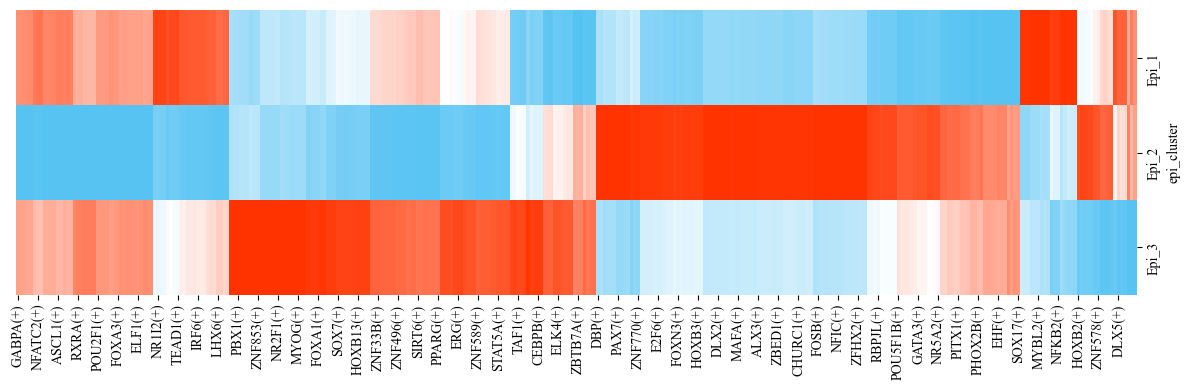

In [24]:
import seaborn as sns
from matplotlib import colors
import matplotlib.pyplot as plt

import matplotlib.font_manager as fm
font_dir = '/data/work/GZ_lab/ovarian/font/'
for ttf in fm.findSystemFonts(font_dir):
    fm.fontManager.addfont(ttf)

import matplotlib
plt.rcParams['font.family'] = 'Times New Roman'
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42

import logging
logging.getLogger("fontTools.subset").setLevel(logging.WARNING)

custom_colors = ["#57C3F3", "white", "#FF3300"]
cmap_custom = colors.LinearSegmentedColormap.from_list("my_gradient", custom_colors, N=128)

sns.clustermap(df_z, cmap=cmap_custom,
               col_cluster=True, row_cluster=False,
               figsize=(12, 4), cbar_pos=None, dendrogram_ratio=0)
plt.savefig('./fig/fig3_tf_epi_specific_heatmap.pdf', format='pdf')

In [25]:
from pyscenic.rss import regulon_specificity_scores

In [26]:
cell_labels = (selected_data.obs['anno_I'].astype(str))
rss_df = regulon_specificity_scores(auc_mtx, cell_labels)

In [27]:
rss_df

,ALX3(+),ARID3A(+),ASCL1(+),ATF1(+),ATF3(+),ATF4(+),BARX1(+),BCL11A(+),BCL6(+),BHLHE22(+),...,ZNF775(+),ZNF780A(+),ZNF792(+),ZNF816(+),ZNF845(+),ZNF846(+),ZNF853(+),ZNF891(+),ZSCAN1(+),ZSCAN23(+)
Epi_1,0.190220,0.295204,0.297889,0.248930,0.256154,0.306374,0.303206,0.318821,0.301470,0.349674,...,0.273516,0.261840,0.233447,0.233309,0.303592,0.285001,0.276350,0.207233,0.305657,0.214963
Epi_3,0.259888,0.505041,0.418848,0.329068,0.426253,0.434599,0.418134,0.532494,0.484437,0.380956,...,0.351809,0.437648,0.326622,0.297490,0.510661,0.437638,0.427531,0.276566,0.515639,0.267633
Epi_2,0.322230,0.298229,0.248969,0.282578,0.286067,0.310081,0.304514,0.260236,0.287954,0.299127,...,0.257038,0.270507,0.285107,0.207960,0.302476,0.276158,0.275118,0.291878,0.279819,0.213888


In [28]:
rss_z = zscore(zscore(rss_df, axis=0).dropna(axis=1), axis=1)

In [29]:
rss_z

,ALX3(+),ARID3A(+),ASCL1(+),ATF1(+),ATF3(+),ATF4(+),BARX1(+),BCL11A(+),BCL6(+),BHLHE22(+),...,ZNF775(+),ZNF780A(+),ZNF792(+),ZNF816(+),ZNF845(+),ZNF846(+),ZNF853(+),ZNF891(+),ZSCAN1(+),ZSCAN23(+)
Epi_1,-1.452471,-0.036891,1.005652,-1.203088,-0.513987,-0.078829,-0.028139,0.720768,0.211777,2.427871,...,0.568019,-0.138245,-1.506291,0.986152,0.019944,0.167842,0.027826,-1.849166,0.344364,0.062644
Epi_3,-3.320675,0.439310,0.284554,0.083798,0.386569,0.438364,0.439426,0.357590,0.432244,-0.373084,...,0.387846,0.435900,-0.209330,0.290219,0.439575,0.435007,0.439521,-2.101942,0.420190,0.439023
Epi_2,2.921549,-0.244623,-0.796211,0.694242,0.083030,-0.218068,-0.250115,-0.664205,-0.394361,-1.276811,...,-0.588005,-0.179763,1.060536,-0.787581,-0.279991,-0.368827,-0.284841,2.425255,-0.469153,-0.306106


In [30]:
rss_melt_df = rss_df.reset_index().melt(id_vars='index', var_name='regulon', value_name='RSS')
print(rss_melt_df.head())
rss_z = rss_z.reset_index().melt(id_vars='index', var_name='regulon', value_name='z_score')
print(rss_z.head())

   index    regulon       RSS
0  Epi_1    ALX3(+)  0.190220
1  Epi_3    ALX3(+)  0.259888
2  Epi_2    ALX3(+)  0.322230
3  Epi_1  ARID3A(+)  0.295204
4  Epi_3  ARID3A(+)  0.505041
   index    regulon   z_score
0  Epi_1    ALX3(+) -1.452471
1  Epi_3    ALX3(+) -3.320675
2  Epi_2    ALX3(+)  2.921549
3  Epi_1  ARID3A(+) -0.036891
4  Epi_3  ARID3A(+)  0.439310


In [31]:
rss_melt_df = rss_melt_df.merge(rss_z, on=['index', 'regulon'], how='inner')

In [32]:
rss_melt_df.head()

,index,regulon,RSS,z_score
0,Epi_1,ALX3(+),0.190220,-1.452471
1,Epi_3,ALX3(+),0.259888,-3.320675
2,Epi_2,ALX3(+),0.322230,2.921549
3,Epi_1,ARID3A(+),0.295204,-0.036891
4,Epi_3,ARID3A(+),0.505041,0.439310


In [33]:
top_rss_df = rss_df.stack().reset_index().rename(columns={0:'RSS'}).groupby('level_0').apply(lambda x: x.nlargest(10, 'RSS')).reset_index(drop=True).rename(columns={'level_0': 'index', 'level_1': 'regulon'})
top_rss_df = top_rss_df.merge(rss_z, on=['index', 'regulon'], how='inner')

meta NOT subset; don't know how to subset; dropped


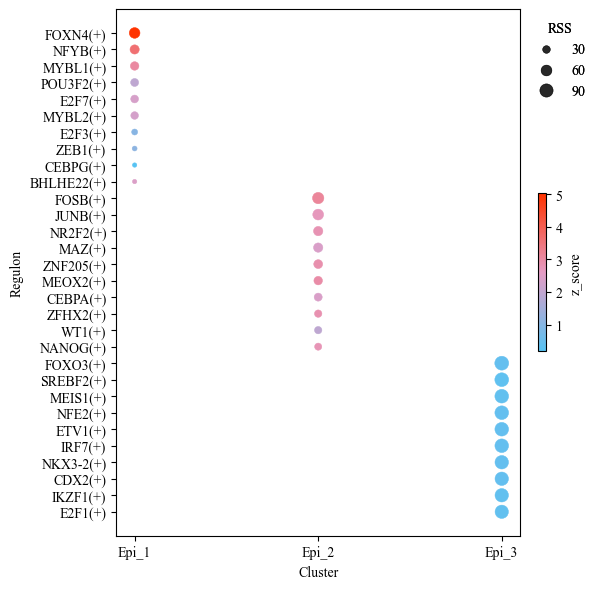

In [34]:
import matplotlib as mpl

plt.figure(figsize=(6, 6))

custom_colors = ["#57C3F3", "#E59CC4", "#FF3300"]
cmap_custom = colors.LinearSegmentedColormap.from_list("my_gradient", custom_colors, N=128)

scp = sns.scatterplot(data=top_rss_df,
                x='index', y='regulon',
                size='RSS', hue='z_score',
                sizes=(10, 100),  # 最小/最大点大小
                palette=cmap_custom, edgecolor=None)

if scp.legend_ is not None:
    scp.legend_.remove()
scatter_obj = scp.collections[0]

handles, labels = scatter_obj.legend_elements(prop="sizes", num=3, alpha=0.6)
size_legend = plt.legend(
    handles, labels,
    title="RSS",
    bbox_to_anchor=(1, 1),
    loc='upper left',
    frameon=False
)
plt.gca().add_artist(size_legend)

norm = mpl.colors.Normalize(
    vmin=top_rss_df['z_score'].min(),
    vmax=top_rss_df['z_score'].max()
)
sm = plt.cm.ScalarMappable(cmap=cmap_custom, norm=norm)
sm.set_array([])

cbar = plt.colorbar(sm, ax=plt.gca(), fraction=0.05, pad=0.04, shrink=0.3)
cbar.set_label("z_score")


plt.xlabel("Cluster")
plt.ylabel("Regulon")
plt.xticks(rotation=0)

plt.tight_layout()
plt.savefig('./fig/fig3_tf_epi_sepcific_top_scatter.pdf', format='pdf')
plt.show()

Looks like you are using a tranform that doesn't support FancyArrowPatch, using ax.annotate instead. The arrows might strike through texts. Increasing shrinkA in arrowprops might help.
meta NOT subset; don't know how to subset; dropped


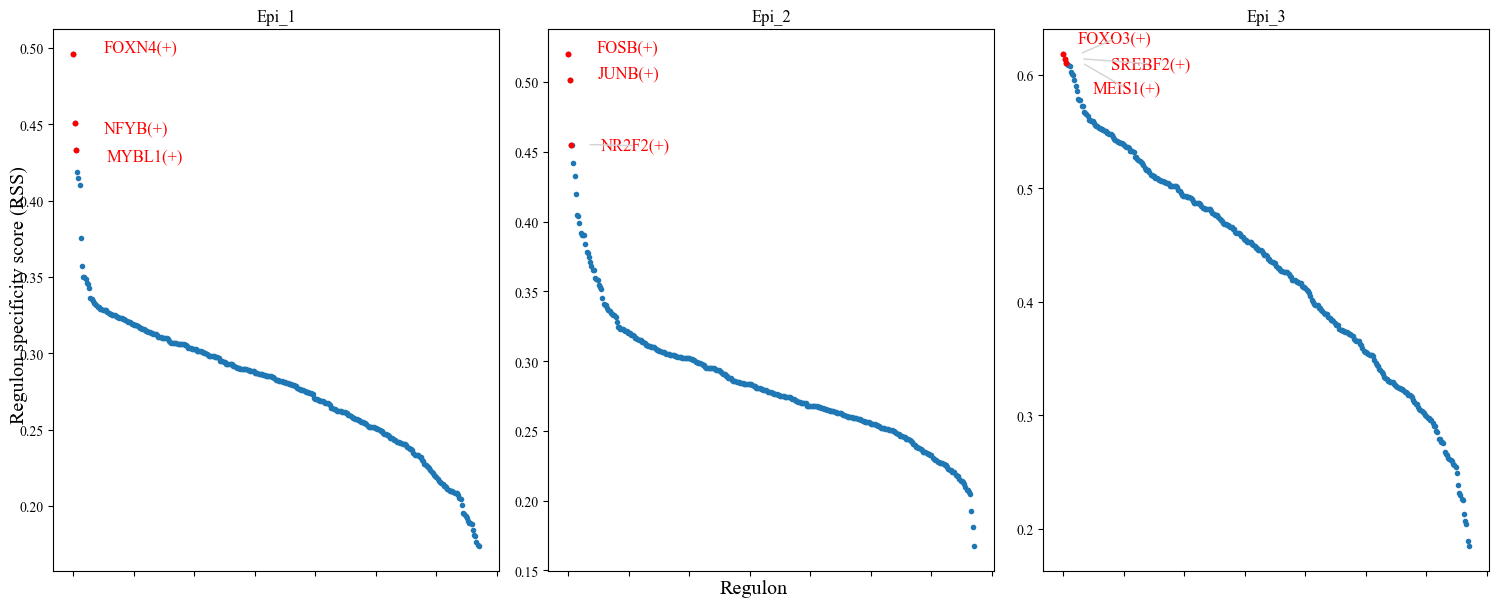

In [35]:
from pyscenic.plotting import plot_rss
from adjustText import adjust_text

cats = sorted(list(set(selected_data.obs['anno_I'])), key=str)

fig = plt.figure(figsize=(15, 6))

for c,num in zip(cats, range(1,len(cats)+1)):
    x=rss_df.T[c]
    ax = fig.add_subplot(1,3,num)
    plot_rss(rss_df, c, top_n=3, max_n=None, ax=ax)
    ax.set_ylim( x.min()-(x.max()-x.min())*0.05 , x.max()+(x.max()-x.min())*0.05 )
    for t in ax.texts:
        t.set_fontsize(12)
    ax.set_ylabel('')
    ax.set_xlabel('')
    adjust_text(ax.texts, autoalign='xy', ha='right', va='bottom', arrowprops=dict(arrowstyle='-',color='lightgrey'), precision=0.001 )

plt.rcParams.update({'figure.autolayout': False})
plt.tight_layout(rect=[0.06, 0.06, 0.98, 0.96])

fig.text(0.5, 0.01, 'Regulon', ha='center', va='center', size='x-large')
fig.text(0.01, 0.5, 'Regulon specificity score (RSS)', ha='center', va='center', rotation='vertical', size='x-large')

plt.rcParams.update({
    'figure.autolayout': True,
        'figure.titlesize': 'large' ,
        'axes.labelsize': 'medium',
        'axes.titlesize':'large',
        'xtick.labelsize':'medium',
        'ytick.labelsize':'medium'
        })

plt.savefig('./fig/fig3_top3_tf_in_celltype.pdf', bbox_inches='tight', pad_inches=0.2)
plt.show()

In [55]:
cnv_result = pd.read_csv('02_monocle_meta.tsv.gz', sep='\t', header=None, index_col=0)
cnv_result.columns = ['group', 'anno_I', 'cnv_leiden', 'cnv_score']
cnv_result.head()

,group,anno_I,cnv_leiden,cnv_score
0,,,,
CCGTCCGGTG_AACAGCATAG_L1,Cancer,Epi_1,0,0.078686
TACAAGCACC_AACAGCATAG_L1,Cancer,Epi_3,0,0.028438
ACCTCGTGAA_AACCTAGTAG_L1,Cancer,Epi_1,0,0.101474
TTATGACCGG_AACCTAGTAG_L1,Cancer,Epi_1,0,0.050504
AGTTGCGATA_AACCTTGCGG_L1,Cancer,Epi_1,0,0.090240


In [56]:
epi = adata[cnv_result.index].copy()
sc.pp.filter_genes(epi, min_cells=1)
epi

AnnData object with n_obs × n_vars = 1920 × 18698
    obs: 'barcodes', 'batch', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rb', 'pct_counts_rb', 'total_counts_hb', 'pct_counts_hb', 'total_counts_hsp', 'pct_counts_hsp', 'n_genes', 'group', 'predicted_celltype', 'predicted_probability', 'leiden', 'anno_I', 'FOXN4(+)', 'FOSB(+)', 'FOXO3(+)', 'E2F1(+)', 'MAZ(+)'
    var: 'mt', 'rb', 'hb', 'hsp', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'n_cells', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'highly_variable_nbatches'
    uns: 'anno_I_colors', 'batch_colors', 'group_colors', 'hvg', 'leiden', 'leiden_colors', 'log1p', 'neighbors', 'over_clustering', 'pca', 'predicted_celltype_colors', 'rank_genes_groups', 'umap'
    obsm: 'X_pca', 'X_pca_harmony', 'X_umap'
    varm: 'PCs'
    layers: 'counts'
    obsp: 'connectivities', 'distances'

In [57]:
sc.tl.umap(epi, min_dist=0.3, random_state=0)

/opt/software/python/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


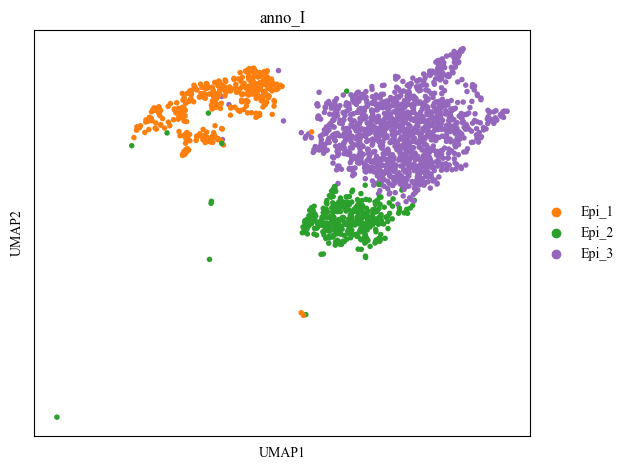

In [58]:
sc.pl.umap(epi, color='anno_I')

meta NOT subset; don't know how to subset; dropped


<Figure size 400x400 with 0 Axes>

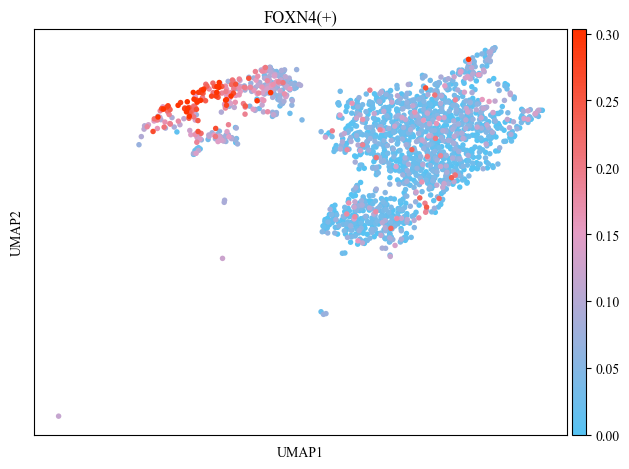

In [59]:
epi.obs['FOXN4(+)'] = auc_mtx['FOXN4(+)'].reindex(epi.obs_names, fill_value=0)

plt.figure(figsize=(4,4))
sc.pl.umap(epi, color='FOXN4(+)', vmax='p99', vmin='p1', cmap=cmap_custom, show=False)

plt.savefig('./fig/fig3_Epi-1_tf_umap.pdf', format='pdf')

meta NOT subset; don't know how to subset; dropped


<Figure size 400x400 with 0 Axes>

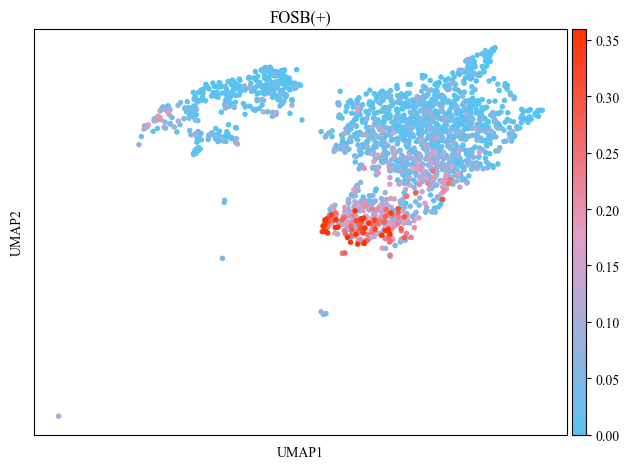

In [60]:
epi.obs['FOSB(+)'] = auc_mtx['FOSB(+)'].reindex(epi.obs_names, fill_value=0)

plt.figure(figsize=(4,4))
sc.pl.umap(epi, color='FOSB(+)', vmax='p99', vmin='p1', cmap=cmap_custom, show=False)

plt.savefig('./fig/fig3_Epi-2_tf_umap.pdf', format='pdf')

meta NOT subset; don't know how to subset; dropped


<Figure size 400x400 with 0 Axes>

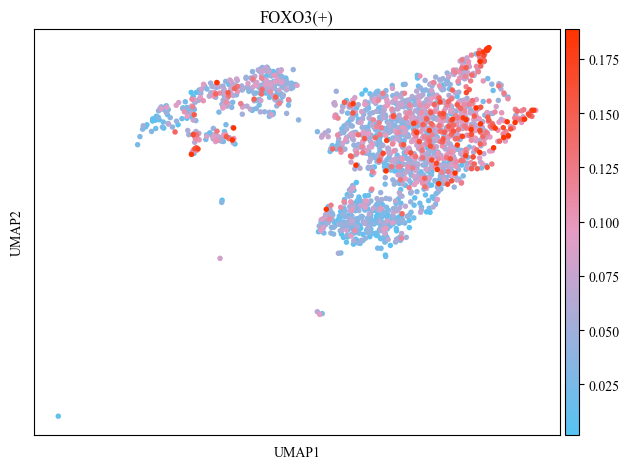

In [61]:
epi.obs['FOXO3(+)'] = auc_mtx['FOXO3(+)'].reindex(epi.obs_names, fill_value=0)

plt.figure(figsize=(4,4))
sc.pl.umap(epi, color='FOXO3(+)', vmax='p99', vmin='p1', cmap=cmap_custom, show=False)

plt.savefig('./fig/fig3_Epi-3_tf_umap.pdf', format='pdf')

In [39]:
cnv_result = pd.read_csv('02_monocle_meta.tsv.gz', sep='\t', header=None, index_col=0)
cnv_result.columns = ['group', 'anno_I', 'cnv_leiden', 'cnv_score']
cnv_result.head()

,group,anno_I,cnv_leiden,cnv_score
0,,,,
CCGTCCGGTG_AACAGCATAG_L1,Cancer,Epi_1,0,0.078686
TACAAGCACC_AACAGCATAG_L1,Cancer,Epi_3,0,0.028438
ACCTCGTGAA_AACCTAGTAG_L1,Cancer,Epi_1,0,0.101474
TTATGACCGG_AACCTAGTAG_L1,Cancer,Epi_1,0,0.050504
AGTTGCGATA_AACCTTGCGG_L1,Cancer,Epi_1,0,0.090240


In [40]:
cnv_res = pd.read_csv('02_monocle_meta.tsv.gz', sep='\t', header=None, index_col=0)
cnv_res.columns = ['group', 'celltype', 'cnv_leiden', 'score']
cnv_res.head()

,group,celltype,cnv_leiden,score
0,,,,
CCGTCCGGTG_AACAGCATAG_L1,Cancer,Epi_1,0,0.078686
TACAAGCACC_AACAGCATAG_L1,Cancer,Epi_3,0,0.028438
ACCTCGTGAA_AACCTAGTAG_L1,Cancer,Epi_1,0,0.101474
TTATGACCGG_AACCTAGTAG_L1,Cancer,Epi_1,0,0.050504
AGTTGCGATA_AACCTTGCGG_L1,Cancer,Epi_1,0,0.090240


In [41]:
cnv_cluster_df = auc_mtx.copy()
cnv_cluster_df = cnv_cluster_df.loc[cnv_res.index]
cnv_cluster_df['cnv_cluster'] = cnv_res['cnv_leiden']

In [42]:
cnv_plot_df = cnv_cluster_df.groupby('cnv_cluster').mean()
cnv_plot_df.head()

,ALX3(+),ARID3A(+),ASCL1(+),ATF1(+),ATF3(+),ATF4(+),BARX1(+),BCL11A(+),BCL6(+),BHLHE22(+),...,ZNF775(+),ZNF780A(+),ZNF792(+),ZNF816(+),ZNF845(+),ZNF846(+),ZNF853(+),ZNF891(+),ZSCAN1(+),ZSCAN23(+)
cnv_cluster,,,,,,,,,,,,,,,,,,,,,
0,0.001505,0.014772,0.036151,0.035284,0.022749,0.024083,0.009956,0.042029,0.015754,0.017800,...,0.014605,0.016113,0.018754,0.009563,0.020957,0.030798,0.021157,0.004980,0.037200,0.008576
2,0.019186,0.018956,0.019252,0.050506,0.029054,0.028157,0.010593,0.027190,0.015807,0.022271,...,0.011605,0.015560,0.031846,0.003404,0.022829,0.029193,0.023646,0.015665,0.036348,0.011930


meta NOT subset; don't know how to subset; dropped


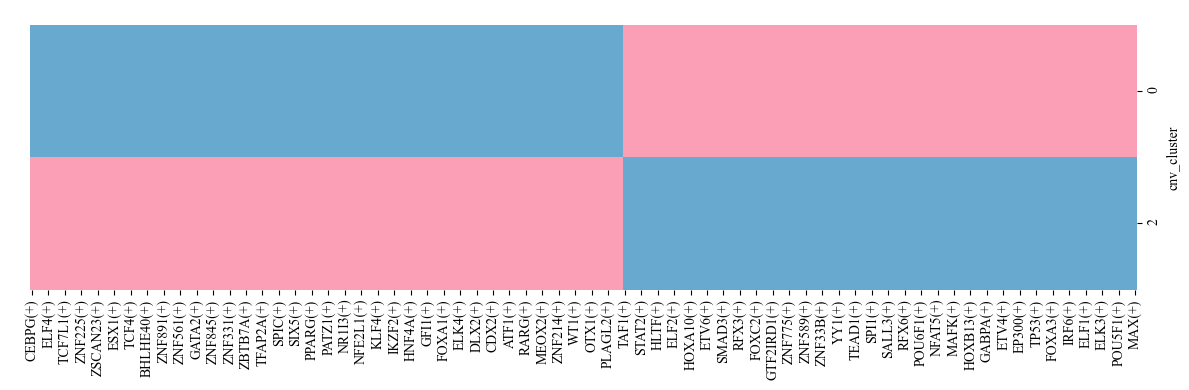

In [49]:
df_z = zscore(cnv_plot_df)
df_z.replace([np.inf, -np.inf], np.nan, inplace=True)
df_z = df_z.dropna(axis=1)

custom_colors = ["#67a9cf", "#fa9fb5"]
cmap_custom = colors.LinearSegmentedColormap.from_list("my_gradient", custom_colors, N=128)

sns.clustermap(df_z, cmap=cmap_custom,
               col_cluster=True, row_cluster=False,
               figsize=(12, 4), cbar_pos=None, dendrogram_ratio=0)
plt.savefig('./fig/fig3_tf_cnv_specific_heatmap.pdf', format='pdf')

meta NOT subset; don't know how to subset; dropped


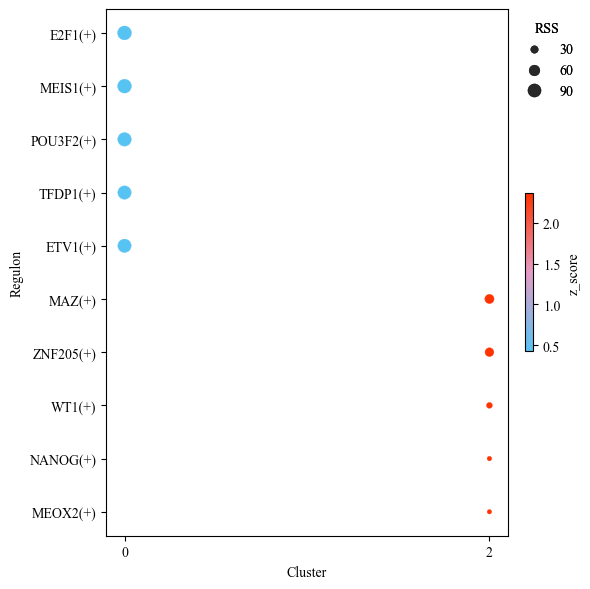

In [50]:
cell_labels = (cnv_res['cnv_leiden'].astype(str))
rss_df = regulon_specificity_scores(auc_mtx, cell_labels)

rss_z = zscore(zscore(rss_df, axis=0).dropna(axis=1), axis=1)

rss_melt_df = rss_df.reset_index().melt(id_vars='index', var_name='regulon', value_name='RSS')
rss_z = rss_z.reset_index().melt(id_vars='index', var_name='regulon', value_name='z_score')
rss_melt_df = rss_melt_df.merge(rss_z, on=['index', 'regulon'], how='inner')

top_rss_df = rss_df.stack().reset_index().rename(columns={0:'RSS'}).groupby('level_0').apply(lambda x: x.nlargest(5, 'RSS')).reset_index(drop=True).rename(columns={'level_0': 'index', 'level_1': 'regulon'})
top_rss_df = top_rss_df.merge(rss_z, on=['index', 'regulon'], how='inner')

import matplotlib as mpl

plt.figure(figsize=(6, 6))

custom_colors = ["#57C3F3", "#E59CC4", "#FF3300"]
cmap_custom = colors.LinearSegmentedColormap.from_list("my_gradient", custom_colors, N=128)

scp = sns.scatterplot(data=top_rss_df,
                x='index', y='regulon',
                size='RSS', hue='z_score',
                sizes=(10, 100),  # 最小/最大点大小
                palette=cmap_custom, edgecolor=None)

if scp.legend_ is not None:
    scp.legend_.remove()
scatter_obj = scp.collections[0]

handles, labels = scatter_obj.legend_elements(prop="sizes", num=3, alpha=0.6)
size_legend = plt.legend(
    handles, labels,
    title="RSS",
    bbox_to_anchor=(1, 1),
    loc='upper left',
    frameon=False
)
plt.gca().add_artist(size_legend)

norm = mpl.colors.Normalize(
    vmin=top_rss_df['z_score'].min(),
    vmax=top_rss_df['z_score'].max()
)
sm = plt.cm.ScalarMappable(cmap=cmap_custom, norm=norm)
sm.set_array([])

cbar = plt.colorbar(sm, ax=plt.gca(), fraction=0.05, pad=0.04, shrink=0.3)
cbar.set_label("z_score")


plt.xlabel("Cluster")
plt.ylabel("Regulon")
plt.xticks(rotation=0)

plt.tight_layout()
plt.savefig('./fig/fig3_tf_cnv_sepcific_top_scatter.pdf', format='pdf')
plt.show()

meta NOT subset; don't know how to subset; dropped


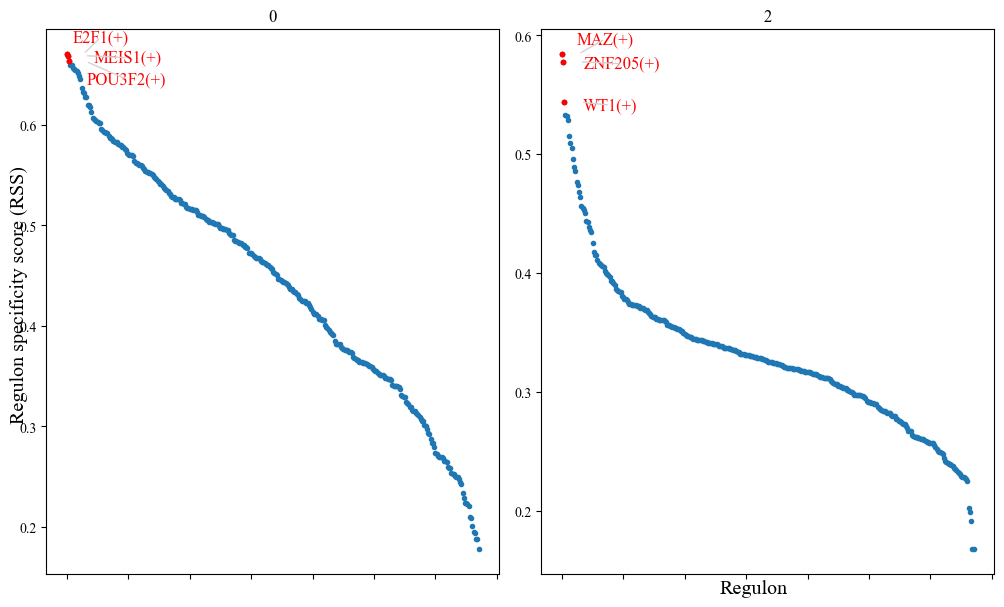

In [51]:
from pyscenic.plotting import plot_rss
from adjustText import adjust_text

cats = sorted(cnv_res['cnv_leiden'].unique(), key=int)

fig = plt.figure(figsize=(15, 6))

for c,num in zip(cats, range(1,len(cats)+1)):
    c = str(c)
    x=rss_df.T[c]
    ax = fig.add_subplot(1,3,num)
    plot_rss(rss_df, c, top_n=3, max_n=None, ax=ax)
    ax.set_ylim( x.min()-(x.max()-x.min())*0.05 , x.max()+(x.max()-x.min())*0.05 )
    for t in ax.texts:
        t.set_fontsize(12)
    ax.set_ylabel('')
    ax.set_xlabel('')
    adjust_text(ax.texts, autoalign='xy', ha='right', va='bottom', arrowprops=dict(arrowstyle='-',color='lightgrey'), precision=0.001 )

plt.rcParams.update({'figure.autolayout': False})
plt.tight_layout(rect=[0.06, 0.06, 0.98, 0.96])

fig.text(0.5, 0.01, 'Regulon', ha='center', va='center', size='x-large')
fig.text(0.01, 0.5, 'Regulon specificity score (RSS)', ha='center', va='center', rotation='vertical', size='x-large')

plt.rcParams.update({
    'figure.autolayout': True,
        'figure.titlesize': 'large' ,
        'axes.labelsize': 'medium',
        'axes.titlesize':'large',
        'xtick.labelsize':'medium',
        'ytick.labelsize':'medium'
        })

plt.savefig('./fig/fig3_top3_tf_in_cnv_leiden.pdf', bbox_inches='tight', pad_inches=0.2)
plt.show()

meta NOT subset; don't know how to subset; dropped


<Figure size 400x400 with 0 Axes>

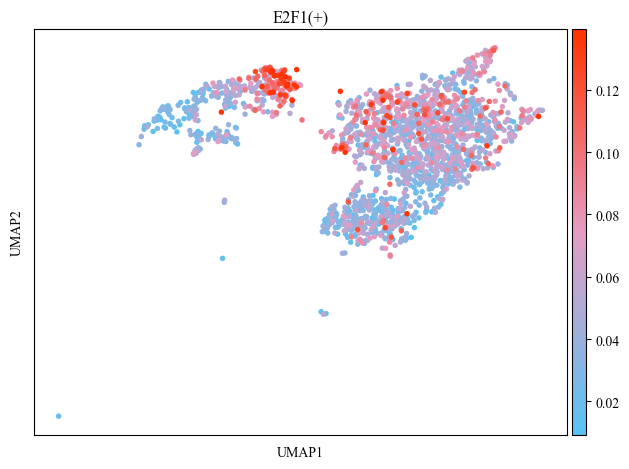

In [62]:
epi.obs['E2F1(+)'] = auc_mtx['E2F1(+)'].reindex(epi.obs_names, fill_value=0)

plt.figure(figsize=(4,4))
sc.pl.umap(epi, color='E2F1(+)', vmax='p99', vmin='p1', cmap=cmap_custom, show=False)

plt.savefig('./fig/fig3_CNV_leiden_1_umap.pdf', format='pdf')

meta NOT subset; don't know how to subset; dropped


<Figure size 400x400 with 0 Axes>

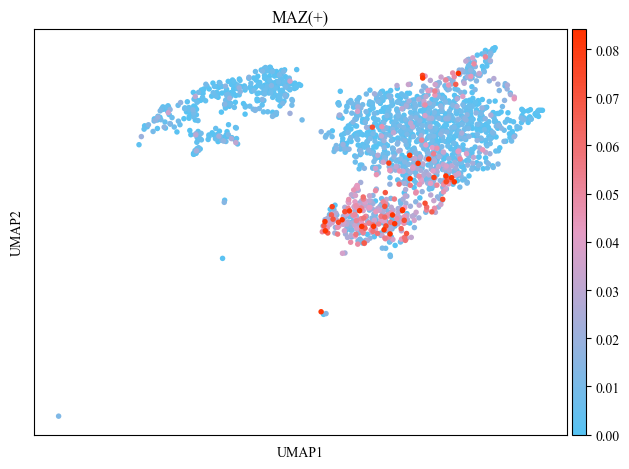

In [63]:
epi.obs['MAZ(+)'] = auc_mtx['MAZ(+)'].reindex(epi.obs_names, fill_value=0)

plt.figure(figsize=(4,4))
sc.pl.umap(epi, color='MAZ(+)', vmax='p99', vmin='p1', cmap=cmap_custom, show=False)

plt.savefig('./fig/fig3_CNV_leiden_2_umap.pdf', format='pdf')

meta NOT subset; don't know how to subset; dropped


<Figure size 400x400 with 0 Axes>

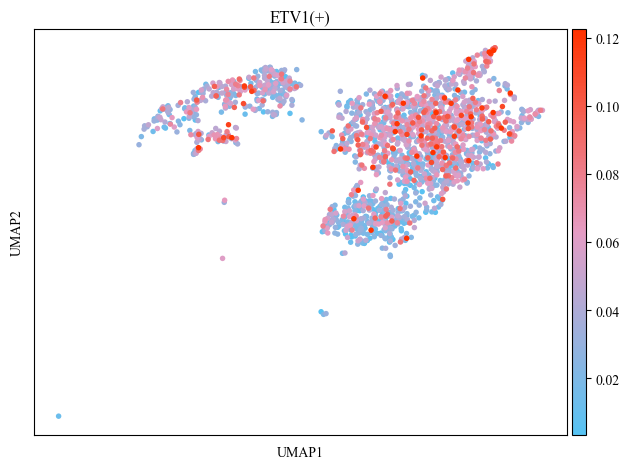

In [64]:
epi.obs['ETV1(+)'] = auc_mtx['ETV1(+)'].reindex(epi.obs_names, fill_value=0)

plt.figure(figsize=(4,4))
sc.pl.umap(epi, color='ETV1(+)', vmax='p99', vmin='p1', cmap=cmap_custom, show=False)

plt.savefig('./fig/fig3_common_umap.pdf', format='pdf')